# 3 · Router

**Módulo 1 · Introducción.** El proyecto del módulo es un agente de cálculo simbólico. La lección 2 terminó con un pedido de herramienta que nadie respondía. Esta lección agrega el nodo que lo responde, `tools`, y una arista condicional que decide si pasar por él. El modelo decide una sola vez y el grafo no tiene ciclos, así que lo último que se escribe es el resultado de la herramienta: el modelo nunca lo ve. Devolverle ese resultado es la lección 4.

Se definen el nodo de herramientas, lo que hace cuando un pedido falla, la arista `tools_condition` y el router, y se prueba cuáles son sus estados finales.

**Dónde corre.** Las secciones 1 a 5 y la profundización no usan el modelo y corren en el PC: en su lugar va un modelo guionado, que escribe siempre el mismo mensaje. La sección 6 usa `qwen3:8b`, que corre en Kaggle con una GPU; el [índice del módulo](README.md) explica cómo abrir el notebook allí.

Requisito: `pip install "langgraph>=1.2" "langchain-ollama>=1.1" "sympy>=1.14"`. Las salidas de este notebook son de langgraph 1.2.17, langgraph-prebuilt 1.1.1, langchain-core 1.7.0, langchain-ollama 1.1.0, sympy 1.14.0 y Ollama 0.40.13 con `qwen3:8b`, en una GPU T4 de Kaggle.

**Preparación.** En Kaggle, la celda siguiente instala las dependencias y Ollama, arranca el servidor y descarga `qwen3:8b`, en poco más de un minuto. En el PC no hace nada.

In [1]:
import os
import subprocess
import time
import urllib.request

EN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ


def correr(comando: str) -> None:
    """Corre un comando de shell y, si falla, muestra el final de su error."""
    r = subprocess.run(comando, shell=True, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"falló: {comando}\n{r.stderr[-2000:]}")


def preparar_kaggle() -> None:
    """Instala las dependencias y Ollama, arranca el servidor y descarga qwen3:8b."""
    correr("pip install -q 'langgraph==1.2.17' 'langgraph-prebuilt==1.1.1' 'langchain-core==1.7.0'"
           " 'langchain-ollama==1.1.0' 'sympy==1.14.0'")
    correr("(command -v zstd || (apt-get -qq update && apt-get -qq install -y zstd))"
           " && curl -fsSL https://ollama.com/install.sh | sh")
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(60):
        try:
            urllib.request.urlopen("http://127.0.0.1:11434/api/version")
            break
        except OSError:
            time.sleep(1)
    else:
        raise RuntimeError("el servidor de Ollama no respondió en 60 s")
    correr("ollama pull qwen3:8b")


if EN_KAGGLE:
    preparar_kaggle()

In [2]:
from importlib.metadata import version

for paquete in ("langgraph", "langgraph-prebuilt", "langchain-core", "langchain-ollama", "sympy"):
    print(paquete, version(paquete))

langgraph 1.2.17
langgraph-prebuilt 1.1.1
langchain-core 1.7.0
langchain-ollama 1.1.0
sympy 1.14.0


## 1. El problema

Por la Proposición 2.8, el grafo $\texttt{START} \to \texttt{modelo} \to \texttt{END}$ termina en $e \oplus (m)$. Si $m$ trae pedidos de herramienta, quedan sin responder. Faltan dos piezas:

1. un nodo que responda los pedidos, es decir, que calcule $f_n(x)$ y escriba un mensaje de herramienta con el identificador $\gamma$ (Definición 2.6), como se hizo a mano al final de la lección 2;
2. una arista condicional que lleve a ese nodo solo cuando hay pedidos, porque si el modelo respondió con texto no hay nada que ejecutar.

Con las dos, una ejecución sigue uno de dos caminos: $\texttt{START} \to \texttt{modelo} \to \texttt{END}$ o $\texttt{START} \to \texttt{modelo} \to \texttt{tools} \to \texttt{END}$. A ese grafo se le llama router: el modelo decide una vez por dónde sigue la ejecución.

**Mapa de la lección.** El router, ejecutado dos veces: con un pedido que el modelo responde con texto y con uno que pasa por `tools`. El nodo `tools` se define en las secciones 2 y 3, la arista en la 4 y el grafo en la 5; la sección 6 lo corre con el modelo.

<img src="../../imagenes/diagramas/modulo-1/router.svg" alt="El router: START lleva a modelo; de modelo, una arista condicional va a tools si el último mensaje trae pedidos y a END si no; tools lleva a END. Primero corre ¿Cuánto es 2 + 2?: el modelo responde 4 y la ejecución va directo a END. Después corre Deriva x³: el modelo pide derivar(x**3), tools escribe el mensaje 3*x**2 y la ejecución termina sin volver al modelo" width="640">

Las herramientas son las de la lección 2:

In [3]:
from sympy import Symbol, diff, integrate, solve
from sympy.parsing.sympy_parser import convert_xor, parse_expr, standard_transformations

TRANSFORMACIONES = standard_transformations + (convert_xor,)


def leer(texto: str):
    """Convierte texto en sintaxis de SymPy en una expresión; «^» vale como potencia."""
    return parse_expr(texto, transformations=TRANSFORMACIONES)


def derivar(expresion: str, variable: str = "x") -> str:
    """Deriva una expresión respecto de una variable.

    Args:
        expresion: expresión en sintaxis de SymPy, por ejemplo x**2*sin(x).
        variable: variable respecto de la que se deriva.
    """
    return str(diff(leer(expresion), Symbol(variable)))


def integrar(expresion: str, variable: str = "x") -> str:
    """Calcula una primitiva de una expresión, sin constante de integración.

    Args:
        expresion: expresión en sintaxis de SymPy, por ejemplo 1/(1 + x**2).
        variable: variable de integración.
    """
    return str(integrate(leer(expresion), Symbol(variable)))


def resolver(ecuacion: str, variable: str = "x") -> str:
    """Resuelve una ecuación en una incógnita y devuelve la lista de soluciones.

    Args:
        ecuacion: ecuación en sintaxis de SymPy, por ejemplo x**2 - 2 = 0. Sin signo =, se iguala a cero.
        variable: incógnita.
    """
    izquierda, _, derecha = ecuacion.replace("==", "=").partition("=")  # «==», como en Python, vale como «=»
    return str(solve(leer(izquierda) - leer(derecha or "0"), Symbol(variable)))


HERRAMIENTAS = [derivar, integrar, resolver]

## 2. El nodo de herramientas

**Definición 3.1 (nodo de herramientas).** Sea $H$ un conjunto finito de herramientas con nombres distintos, y sea $S_{\text{ai}}$ el conjunto de estados en los que $s(\text{messages})$ tiene algún mensaje de rol ai. Para $s \in S_{\text{ai}}$, sea $m$ el último mensaje de rol ai de $s(\text{messages})$, y sean $p_1, \dots, p_k$ sus pedidos, con $p_j = (n_j, x_j, \gamma_j)$. El nodo de herramientas de $H$ es

$$\varphi_H(s) = \{\text{messages}: (t_1, \dots, t_k)\},$$

donde $t_j$, la respuesta a $p_j$, es el mensaje de herramienta con contenido $f_{n_j}(x_j)$ y `tool_call_id` igual a $\gamma_j$. Si $k = 0$, la actualización es la conversación vacía.

La definición supone que cada pedido se puede responder; la sección 3 trata los que no.

**Observación.** El nodo del modelo toma una muestra (lección 2, §6); $\varphi_H$ no. Salvo los identificadores de los $t_j$, que se asignan al azar, $\varphi_H$ es una función $S_{\text{ai}} \to U$ como los nodos de la lección 1: el mismo estado da siempre los mismos contenidos, porque las funciones de SymPy son deterministas. Fuera de $S_{\text{ai}}$, `ToolNode` lanza `ValueError`.

En LangGraph, $\varphi_H$ es `ToolNode(HERRAMIENTAS)`. En langgraph 1.2, un `ToolNode` no se puede llamar fuera de un grafo: necesita el contexto de ejecución que le pasa el grafo. La función `responder` lo corre en el grafo $\texttt{START} \to \texttt{tools} \to \texttt{END}$, con la conversación que recibe, y devuelve lo que escribe `tools`. `linea` muestra un mensaje en una línea.

In [4]:
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.messages.tool import tool_call
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode

tools = ToolNode(HERRAMIENTAS)


def responder(nodo: ToolNode, mensajes: list, configuracion: dict | None = None) -> list:
    """Corre `nodo` en START → tools → END con la conversación `mensajes` y devuelve lo que escribe."""
    constructor = StateGraph(MessagesState)
    constructor.add_node("tools", nodo)
    constructor.add_edge(START, "tools")
    constructor.add_edge("tools", END)
    for actualizacion in constructor.compile().stream({"messages": mensajes}, configuracion, stream_mode="updates"):
        return actualizacion["tools"]["messages"]


def linea(m) -> str:
    """Rol y contenido de un mensaje; sus pedidos si es de rol ai, y su γ y estado si es de rol tool."""
    if m.type == "ai" and m.tool_calls:
        return "ai    pide " + ", ".join(f"{p['name']}({p['args']}) γ={p['id'][:8]}" for p in m.tool_calls)
    if m.type == "tool":
        return f"tool  {m.content!r}  γ={m.tool_call_id[:8]}  {m.status}"
    return f"{m.type:5} {m.content!r}"

Un mensaje escrito a mano, con dos pedidos:

In [5]:
m = AIMessage("", id="m", tool_calls=[
    tool_call(name="derivar", args={"expresion": "x**3"}, id="g1"),
    tool_call(name="resolver", args={"ecuacion": "x**2 - 2 = 0"}, id="g2"),
])

for t in responder(tools, [m]):
    print(linea(t))

tool  '3*x**2'  γ=g1  success
tool  '[-sqrt(2), sqrt(2)]'  γ=g2  success


Cada $t_j$ lleva el $\gamma_j$ de su pedido, y las respuestas salen en el orden en que están los pedidos. Es lo que se hizo a mano en la lección 2, ahora para todos los pedidos del mensaje en un solo nodo. La profundización muestra que `ToolNode` los responde a la vez, en hilos distintos, y por qué eso no cambia el resultado.

## 3. Cuando un pedido falla

La Definición 2.5 da una función $f : A \to \text{texto}$, y la lección 2 advirtió que nada comprobaba que el modelo escribiera un $x \in A$. Un pedido $(n, x, \gamma)$ puede fallar de tres maneras:

1. $n$ no es el nombre de ninguna herramienta de $H$;
2. $x \notin A_n$: los argumentos no cumplen el esquema, por ejemplo porque falta uno obligatorio o porque tiene otro tipo;
3. $x \in A_n$, pero $f_n$ falla en $x$.

Aquí $A_n$ es el conjunto de argumentos que acepta la validación del esquema; el ejercicio 2 muestra que admite claves de más. El tercer caso existe porque $E$ describe menos de lo que $f$ necesita. El esquema de `derivar` dice que `expresion` es un texto, pero $f$ solo sabe leer los textos en sintaxis de SymPy. La Definición 2.5 trató a $f$ como una función de $A$ en textos; en rigor es parcial: $f_n$ está definida en un subconjunto propio de $A_n$, su dominio $\operatorname{dom} f_n$. Además, antes de llamar a $f$, la validación completa los argumentos que faltan con sus valores por defecto y descarta las claves de más, así que $f$ recibe esa versión normalizada de $x$.

`ToolNode` detecta los dos primeros casos antes de llamar a $f$: busca el nombre y valida $x$ contra $E$ con Pydantic. Con el manejador por defecto, en los dos escribe un mensaje de herramienta con `status="error"` y el texto del error, dirigido al modelo:

In [6]:
fallidos = AIMessage("", id="m", tool_calls=[
    tool_call(name="factorizar", args={"expresion": "x**2 - 1"}, id="g1"),
    tool_call(name="derivar", args={"variable": "x"}, id="g2"),
    tool_call(name="derivar", args={"expresion": 3}, id="g3"),
])

for t in responder(tools, [fallidos]):
    print(linea(t), end="\n\n")

tool  'Error: factorizar is not a valid tool, try one of [derivar, integrar, resolver].'  γ=g1  error

tool  "Error invoking tool 'derivar' with kwargs {'variable': 'x'} with error:\n expresion: Field required\n Please fix the error and try again."  γ=g2  error

tool  "Error invoking tool 'derivar' with kwargs {'expresion': 3} with error:\n expresion: Input should be a valid string\n Please fix the error and try again."  γ=g3  error



El tercer caso es distinto: el error ocurre dentro de $f$, y con la configuración por defecto `ToolNode` no lo atrapa. En langgraph-prebuilt 1.1.1, el manejador por defecto convierte en mensaje solo los errores de validación de Pydantic, que en estas herramientas son los del segundo caso, y vuelve a lanzar cualquier otra excepción, que detiene la ejecución del grafo:

In [7]:
ilegible = AIMessage("", id="m", tool_calls=[tool_call(name="derivar", args={"expresion": "x^^2"}, id="g1")])

try:
    responder(tools, [ilegible])
except Exception as error:
    print(f"{type(error).__name__}: {error}")

SyntaxError: invalid syntax (<string>, line 1)


Con `handle_tool_errors=True`, `ToolNode` atrapa además toda excepción de $f$ y escribe su descripción en un mensaje con `status="error"`:

In [8]:
tools_seguro = ToolNode(HERRAMIENTAS, handle_tool_errors=True)

for t in responder(tools_seguro, [ilegible]):
    print(linea(t))

tool  'Error: SyntaxError(\'invalid syntax\', (\'<string>\', 1, 16, "Symbol (\'x\' )****Integer (2 )", 1, 18))\n Please fix your mistakes.'  γ=g1  error


Desde aquí se supone que cada $f_n$ termina y que, si falla, lanza una excepción de tipo `Exception`, como las de SymPy. `ToolNode` deja pasar siempre las excepciones con que LangGraph interrumpe un grafo, que son tema del módulo 3.

**Definición 3.2 (respuesta a un pedido).** Un pedido $p = (n, x, \gamma)$ es respondible si $n \in H$, $x \in A_n$ y $x \in \operatorname{dom} f_n$. Con `handle_tool_errors=True`, la respuesta a $p$ es un mensaje de herramienta con `tool_call_id` igual a $\gamma$. Si $p$ es respondible, su contenido es $f_n(x)$ y su `status`, `success`. Si no, su contenido describe el error y su `status` es `error`.

Con esta respuesta, $\varphi_H$ de la Definición 3.1 está definida en todo estado que tenga un mensaje de rol ai. Con el manejador por defecto, un pedido con $x \in A_n \setminus \operatorname{dom} f_n$ no tiene respuesta: la ejecución se detiene.

El proyecto usa `tools_seguro`. En el router, el mensaje de error es lo último que se escribe; en el agente de la lección 4, el modelo lo lee y puede corregir la expresión.

**Observación (éxito no es corrección).** `status="success"` solo dice que $f$ no falló. SymPy lee un nombre que no conoce como una función sin definir, y devuelve su derivada sin calcularla:

In [9]:
derivar("foo(x)")

'Derivative(foo(x), x)'

## 4. La arista `tools_condition`

**Definición 3.3 (`tools_condition`).** Sea $S_+$ el conjunto de estados con $s(\text{messages})$ no vacía y, para $s \in S_+$, sea $\ell$ el último mensaje de $s(\text{messages})$. La arista condicional desde el nodo del modelo es la función $c : S_+ \to \{\texttt{tools}, \texttt{END}\}$ con $c(s) = \texttt{tools}$ si $\ell$ trae pedidos, y $c(s) = \texttt{END}$ si no.

Solo un mensaje de rol ai puede traer pedidos. La Definición 1.10 pide una arista definida en todo $S$; aquí basta $S_+$, porque cuando se evalúa $c$ el nodo del modelo ya escribió un mensaje.

`tools_condition` devuelve el texto `"__end__"`, que es el valor de `END`. Mira solo el último mensaje, y con una conversación vacía lanza `ValueError`.

In [10]:
from langgraph.prebuilt import tools_condition

casos = {
    "ai con pedidos": [m],
    "ai sin pedidos": [AIMessage("4")],
    "humano": [HumanMessage("Deriva x³")],
    "tool al final": [m, *responder(tools, [m])],
}
for nombre, mensajes in casos.items():
    print(f"{nombre:15} → {tools_condition({'messages': mensajes})}")
print(repr(END))

ai con pedidos  → tools
ai sin pedidos  → __end__
humano          → __end__
tool al final   → __end__
'__end__'


En el último caso hay un mensaje de rol ai con pedidos, pero no es el último, y la arista va a `END`. `ToolNode`, en cambio, busca el último mensaje de rol ai, no el último mensaje. El ejercicio 3 explora esa diferencia.

## 5. El router

El router tiene el nodo `modelo` de la lección 2, el nodo `tools` y tres aristas: la fija $\texttt{START} \to \texttt{modelo}$, la condicional $c$ desde `modelo` y la fija $\texttt{tools} \to \texttt{END}$. `construir_router` recibe la función del nodo del modelo, para usarlo con el modelo guionado y, en la sección 6, con `qwen3:8b`.

In [11]:
def construir_router(modelo, tools: ToolNode):
    """START → modelo; de modelo, a tools o a END según tools_condition; tools → END."""
    constructor = StateGraph(MessagesState)
    constructor.add_node("modelo", modelo)
    constructor.add_node("tools", tools)
    constructor.add_edge(START, "modelo")
    constructor.add_conditional_edges("modelo", tools_condition)
    constructor.add_edge("tools", END)
    return constructor.compile()

**Definición 3.4 (modelo guionado).** Para un mensaje $m_0$, el modelo guionado escribe $m_0$ con cualquier conversación. Como núcleo (Definición 2.7), $M(\cdot \mid c) = \delta_{m_0}$ para toda $c$: la distribución que da probabilidad 1 a $m_0$.

Reemplaza al modelo para probar el grafo sin GPU y sin el azar del modelo.

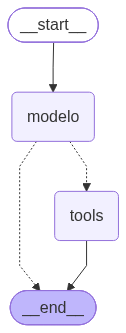

In [12]:
from IPython.display import Image, display


def guionado(m0: AIMessage):
    """El nodo de un modelo guionado: escribe siempre m0."""

    def modelo(s: MessagesState) -> dict:
        return {"messages": [m0]}

    return modelo


router = construir_router(guionado(m), tools_seguro)
display(Image(router.get_graph().draw_mermaid_png()))

Las líneas punteadas son las dos salidas posibles de la arista condicional. LangGraph las conoce sin que se las den: `tools_condition` declara en su anotación de retorno que devuelve `"tools"` o `"__end__"`.

**Proposición 3.5 (estados finales del router).** Sea $e \in C$ una entrada cuyos mensajes tienen identificador, y sea $m$ el mensaje que escribe el nodo del modelo, con un identificador que no está en $\iota(e)$ y con $k$ pedidos $p_1, \dots, p_k$. Con `handle_tool_errors=True` y un `recursion_limit` de al menos 3, como el valor por defecto:

1. si $k = 0$, la ejecución usa dos supersteps y termina en $e \oplus (m)$;
2. si $k \ge 1$, usa tres supersteps y termina en $e \oplus (m) \oplus (t_1, \dots, t_k)$, donde $t_j$ es la respuesta a $p_j$ (Definición 3.2).

En los dos casos, el nodo del modelo corre una sola vez, antes de que exista cualquier $t_j$. Si $k \ge 1$, el último mensaje es $t_k$, de rol tool.

*Demostración.* En el superstep 0, `START` escribe la entrada: $s_0(\text{messages}) = e$. En el superstep 1 corre `modelo`, que escribe $(m)$; como el identificador de $m$ no está en $\iota(e)$, $s_1(\text{messages}) = e \oplus (m)$ termina en $m$. La arista evalúa $c(s_1)$ con $\ell = m$. Si $k = 0$, $c(s_1) = \texttt{END}$ y la ejecución termina tras dos supersteps. Si $k \ge 1$, $c(s_1) = \texttt{tools}$. En el superstep 2, `tools` busca el último mensaje de rol ai de $s_1$, que es $m$, y escribe $(t_1, \dots, t_k)$, que está definida porque `handle_tool_errors=True`. Los $t_j$ reciben identificadores nuevos al azar, así que $\oplus$ los agrega al final, y la arista fija $\texttt{tools} \to \texttt{END}$ termina la ejecución. El nodo del modelo solo corrió en el superstep 1. $\square$

Con el modelo guionado, para $k = 0, 1, 2$:

In [13]:
guiones = {
    0: AIMessage("4", id="m"),
    1: AIMessage("", id="m", tool_calls=[tool_call(name="derivar", args={"expresion": "x**3"}, id="g1")]),
    2: m,
}

for k, m0 in guiones.items():
    router = construir_router(guionado(m0), tools_seguro)
    entrada = {"messages": [HumanMessage("pedido", id="h1")]}
    nodos = [list(u) for u in router.stream(entrada, stream_mode="updates")]
    final = router.invoke(entrada)
    print(f"k = {k}: después de START corren {nodos}")
    for x in final["messages"]:
        print("   ", linea(x))

k = 0: después de START corren [['modelo']]
    human 'pedido'
    ai    '4'
k = 1: después de START corren [['modelo'], ['tools']]
    human 'pedido'
    ai    pide derivar({'expresion': 'x**3'}) γ=g1
    tool  '3*x**2'  γ=g1  success
k = 2: después de START corren [['modelo'], ['tools']]
    human 'pedido'
    ai    pide derivar({'expresion': 'x**3'}) γ=g1, resolver({'ecuacion': 'x**2 - 2 = 0'}) γ=g2
    tool  '3*x**2'  γ=g1  success
    tool  '[-sqrt(2), sqrt(2)]'  γ=g2  success


Con $k \ge 1$, la ejecución termina con el resultado de la herramienta, no con una respuesta del modelo. Si el pedido era «Deriva x³», `3*x**2` ya es la respuesta. Si era «Deriva x³ y después integra el resultado», falta un paso que el router no puede dar: para integrar $3x^2$ el modelo tendría que leerlo.

## 6. El router con `qwen3:8b`

El nodo del modelo es el de la lección 2: antepone el mensaje de sistema $\sigma$ y toma una muestra $m \sim M\left(\cdot \mid (\sigma) \frown s(\text{messages})\right)$ del modelo con las herramientas enlazadas. La primera llamada carga el modelo en la GPU y tarda más de un minuto.

In [14]:
from langchain_core.messages import SystemMessage
from langchain_ollama import ChatOllama

SISTEMA = SystemMessage(
    "Eres un asistente de cálculo. Para derivar, integrar o resolver ecuaciones usa las herramientas. "
    "Escribe las expresiones en sintaxis de SymPy, por ejemplo x**2*sin(x)."
)
llm = ChatOllama(model="qwen3:8b", temperature=0, reasoning=False)
llm_con_herramientas = llm.bind_tools(HERRAMIENTAS)


def modelo(s: MessagesState) -> dict:
    """Toma una muestra del modelo con (σ) ⁀ s(messages)."""
    return {"messages": [llm_con_herramientas.invoke([SISTEMA] + s["messages"])]}


router = construir_router(modelo, tools_seguro)

Los pedidos de la lección 2, ahora con el router:

In [15]:
pedidos = ["Deriva x^2·sen(x)", "Integra 1/(1+x^2)", "Resuelve x^2 - 2 = 0", "¿Cuánto es 2 + 2?"]

for pedido in pedidos:
    final = router.invoke({"messages": [HumanMessage(pedido)]})
    print(f"{pedido}  →  {len(final['messages'])} mensajes")
    for x in final["messages"][1:]:
        print("   ", linea(x))

Deriva x^2·sen(x)  →  3 mensajes
    ai    pide derivar({'expresion': 'x**2*sin(x)', 'variable': 'x'}) γ=17659b3a
    tool  'x**2*cos(x) + 2*x*sin(x)'  γ=17659b3a  success
Integra 1/(1+x^2)  →  3 mensajes
    ai    pide integrar({'expresion': '1/(1 + x**2)', 'variable': 'x'}) γ=fce37021
    tool  'atan(x)'  γ=fce37021  success
Resuelve x^2 - 2 = 0  →  3 mensajes
    ai    pide resolver({'ecuacion': 'x**2 - 2', 'variable': 'x'}) γ=483293d1
    tool  '[-sqrt(2), sqrt(2)]'  γ=483293d1  success
¿Cuánto es 2 + 2?  →  2 mensajes
    ai    '2 + 2 es igual a 4.'


Los tres primeros pasan por `tools` y terminan con 3 mensajes: el pedido, el mensaje del modelo con su pedido de herramienta y la respuesta de `tools`, que es lo último que se escribe. El modelo escribió `variable` aunque no es obligatoria y, para resolver, `x**2 - 2` sin el «= 0», como en la lección 2. El cuarto no trae pedidos: la arista va a `END` y la ejecución termina con 2 mensajes, como en la Proposición 2.8.

El pedido en dos pasos de la lección 2:

In [16]:
final = router.invoke({"messages": [HumanMessage("Deriva x³ y después integra el resultado")]})
for x in final["messages"]:
    print(linea(x))

human 'Deriva x³ y después integra el resultado'
ai    pide derivar({'expresion': 'x**3', 'variable': 'x'}) γ=03a18ab6, integrar({'expresion': 'x**3', 'variable': 'x'}) γ=9b663ebf
tool  '3*x**2'  γ=03a18ab6  success
tool  'x**4/4'  γ=9b663ebf  success


En esta ejecución, el modelo escribió en un solo mensaje dos pedidos, `derivar` e `integrar`, los dos con `x**3`, y `tools` respondió los dos en el mismo superstep. El estado termina con $x^4/4$, una primitiva de $x^3$, cuando lo pedido era una primitiva de $3x^2$, que es $x^3$. El modelo escribió los dos pedidos antes de conocer cualquier resultado (lección 2, §6), así que el segundo no podía usar el primero. Si hubiera pedido solo `derivar`, como en la ejecución guardada en la lección 2, el router terminaría en $3x^2$ y tampoco integraría.

El router sirve cuando el resultado de la herramienta ya es la respuesta. Cuando hace falta otro paso con ese resultado, el modelo tiene que leerlo: hay que agregar la arista $\texttt{tools} \to \texttt{modelo}$, que cierra un ciclo. Ese grafo es el agente de la lección 4.

### Profundización 3.A · Paralelo dentro de un nodo

Cuando $m$ trae $k$ pedidos, `tools` los responde todos en el mismo superstep. No los responde uno tras otro: en `ToolNode._func` (archivo `langgraph/prebuilt/tool_node.py`), los reparte con `executor.map` entre los hilos de un `ThreadPoolExecutor`, una tarea por pedido. El número máximo de hilos es `max_concurrency`, de la configuración de la ejecución. Sin ese valor, es el que pone Python por defecto, $\min(32, \text{núcleos} + 4)$. Así corre con `invoke` y `stream`; con `ainvoke`, `ToolNode` usa corrutinas y `asyncio.gather`.

**Proposición 3.A.1.** Sea `handle_tool_errors=True`. Si la respuesta a cada pedido, sea su resultado o la descripción de su error, depende solo del pedido, también cuando corre a la vez que otros, la actualización $(t_1, \dots, t_k)$ que escribe `tools` es la misma, salvo los identificadores, con cualquier número de hilos y cualquiera sea el orden en que terminen los pedidos.

*Demostración.* Por la hipótesis, el contenido de $t_j$ depende solo de $p_j$: no depende de las otras respuestas, ni del estado, que además no cambia durante el superstep. Calcular los $t_j$ en cualquier orden, o a la vez, da entonces los mismos $t_j$. Además, `executor.map` devuelve los resultados en el orden de sus argumentos, no en el que terminan, así que la sucesión es $(t_1, \dots, t_k)$. $\square$

No hace falta comprobar que un pedido no dependa de otro: un mensaje se escribe completo antes de que se ejecute cualquiera de sus pedidos (lección 2, §6), así que ningún $x_j$ puede usar un resultado $t_i$.

<img src="../../imagenes/diagramas/modulo-1/paralelo-en-nodo.svg" alt="El superstep 2 del router, con tres pedidos: derivar, integrar y resolver. Dentro del nodo tools corren tres hilos a la vez, uno por pedido; terminan en otro orden, primero resolver, después derivar y al final integrar, pero la actualización escribe las respuestas en el orden de los pedidos. Al final, el contraste con el módulo 4: allí son varios nodos en un mismo superstep, cada uno con su actualización, y los reducers las combinan" width="640">

Una herramienta que solo espera muestra el reparto. `cronometrar` le pide a `tools` un `esperar` por cada duración y anota qué hilo corrió cada pedido, cuándo empezó y cuándo terminó, en segundos desde el comienzo:

In [17]:
import threading
import time

REGISTRO = []  # (hilo, segundos, inicio, fin) de cada llamada


def esperar(segundos: float) -> str:
    """Espera unos segundos sin calcular nada.

    Args:
        segundos: cuánto esperar.
    """
    inicio = time.perf_counter()
    time.sleep(segundos)
    REGISTRO.append((threading.current_thread().name.rsplit("_", 1)[-1], segundos, inicio, time.perf_counter()))
    return f"esperé {segundos} s"


def cronometrar(duraciones: list[float], configuracion: dict | None = None) -> None:
    """Responde un pedido de esperar por cada duración y muestra el reparto entre hilos."""
    REGISTRO.clear()
    pedidos = AIMessage("", id="m", tool_calls=[
        tool_call(name="esperar", args={"segundos": d}, id=f"g{j}") for j, d in enumerate(duraciones, 1)
    ])
    t0 = time.perf_counter()
    respuestas = responder(ToolNode([esperar]), [pedidos], configuracion)
    print(f"{configuracion or 'sin max_concurrency'}: {time.perf_counter() - t0:.2f} s en total")
    for hilo, segundos, inicio, fin in sorted(REGISTRO, key=lambda r: r[2]):
        print(f"   hilo {hilo}: esperar({segundos}) de {inicio - t0:.2f} a {fin - t0:.2f} s")
    print("   respuestas en el orden", [t.tool_call_id for t in respuestas])


cronometrar([0.5, 0.5, 0.5])
cronometrar([0.5, 0.5, 0.5], {"max_concurrency": 1})
cronometrar([0.5, 0.5, 0.5], {"max_concurrency": 2})

sin max_concurrency: 0.51 s en total
   hilo 0: esperar(0.5) de 0.01 a 0.51 s
   hilo 1: esperar(0.5) de 0.01 a 0.51 s
   hilo 2: esperar(0.5) de 0.01 a 0.51 s
   respuestas en el orden ['g1', 'g2', 'g3']
{'max_concurrency': 1}: 1.51 s en total
   hilo 0: esperar(0.5) de 0.01 a 0.51 s
   hilo 0: esperar(0.5) de 0.51 a 1.01 s
   hilo 0: esperar(0.5) de 1.01 a 1.51 s
   respuestas en el orden ['g1', 'g2', 'g3']
{'max_concurrency': 2}: 1.01 s en total
   hilo 0: esperar(0.5) de 0.01 a 0.51 s
   hilo 1: esperar(0.5) de 0.01 a 0.51 s
   hilo 0: esperar(0.5) de 0.51 a 1.01 s
   respuestas en el orden ['g1', 'g2', 'g3']


Sin `max_concurrency`, cada pedido corre en su hilo y los tres terminan juntos, en medio segundo. Con un hilo corren uno tras otro, en un segundo y medio. Con dos, los dos primeros corren a la vez y el tercero espera a que se libere el hilo 0: un segundo. En los tres casos, las respuestas salen en el orden de los pedidos.

Con duraciones distintas, los pedidos terminan en otro orden, pero las respuestas no:

In [18]:
cronometrar([0.6, 0.2, 0.4])

sin max_concurrency: 0.61 s en total
   hilo 0: esperar(0.6) de 0.01 a 0.61 s
   hilo 1: esperar(0.2) de 0.01 a 0.21 s
   hilo 2: esperar(0.4) de 0.01 a 0.41 s
   respuestas en el orden ['g1', 'g2', 'g3']


El pedido de 0,2 s termina primero y el de 0,6 s, último, pero las respuestas salen como `g1`, `g2`, `g3`: en el orden de los pedidos, como dice la Proposición 3.A.1.

**Observación (el GIL).** Los hilos ayudan cuando la herramienta espera: a la red, al disco o a otro proceso. Cuando calcula en Python, como SymPy, no ayudan. En CPython, el intérprete habitual y el de Kaggle, un candado global, el GIL (*global interpreter lock*), deja que un solo hilo ejecute código de Python a la vez. Desde Python 3.13 existe además una versión sin GIL, que se instala aparte y no es la de Kaggle. Cuatro integrales, con hilos y con uno solo. La primera vuelta paga la carga de módulos de SymPy y el tiempo de una vuelta varía, así que hay una vuelta de calentamiento, las dos configuraciones se alternan y se toma el mínimo de cinco vueltas:

In [19]:
import time

from sympy.core.cache import clear_cache

integrales = AIMessage("", id="m", tool_calls=[
    tool_call(name="integrar", args={"expresion": e}, id=f"g{j}")
    for j, e in enumerate(["x*exp(x)*sin(x)", "x*exp(x)*cos(x)", "exp(x)*sin(x)**2", "exp(x)*cos(x)**2"], 1)
])

CONFIGURACIONES = {"con hilos": {}, "un hilo": {"max_concurrency": 1}}
tiempos = {nombre: [] for nombre in CONFIGURACIONES}

clear_cache()
responder(tools, [integrales])  # calentamiento
for _ in range(5):
    for nombre, configuracion in CONFIGURACIONES.items():
        clear_cache()  # SymPy guarda resultados intermedios: sin esto, cada vuelta reusaría los de la anterior
        t0 = time.perf_counter()
        responder(tools, [integrales], configuracion)
        tiempos[nombre].append(time.perf_counter() - t0)

for nombre, lista in tiempos.items():
    print(f"{nombre}: mínimo {min(lista):.2f} s, máximo {max(lista):.2f} s")

con hilos: mínimo 0.38 s, máximo 0.40 s
un hilo: mínimo 0.35 s, máximo 0.47 s


Con hilos, las cuatro integrales no tardan menos que con uno solo: en esta ejecución, el mínimo fue 0,38 s con hilos y 0,35 s con uno. Los hilos se turnan el GIL. Con el GIL, para que código de Python calcule a la vez hacen falta procesos distintos; los hilos sí aceleran el código nativo que suelta el GIL, como muchas operaciones de NumPy.

**Dentro de un nodo y entre nodos.** El módulo 4 trata otra forma de paralelismo: varios nodos activos en un mismo superstep (Definición 1.12). Cada uno lee $s_{t-1}$ y escribe su propia actualización, y al cerrar el superstep los reducers las combinan. Aquí hay un solo nodo, y sus $k$ respuestas van en una sola actualización: ningún reducer tiene que combinarlas, y su orden lo fijan los pedidos.

## Resumen

- El **nodo de herramientas** $\varphi_H$ responde los pedidos del último mensaje de rol ai: escribe un mensaje de herramienta por pedido, con el $\gamma$ del pedido. Salvo los identificadores, es una función: no toma muestras. En LangGraph es `ToolNode`.
- Un pedido falla si su nombre no está en $H$, si $x \notin A$ o si $f$ falla en $x$. Con el manejador por defecto, `ToolNode` escribe un mensaje con `status="error"` en los dos primeros casos y detiene el grafo en el tercero; con `handle_tool_errors=True`, escribe el mensaje en los tres. `status="success"` no garantiza que el resultado tenga sentido.
- `tools_condition` es la arista condicional que va a `tools` si el último mensaje trae pedidos y a `END` si no.
- El **router** tiene las aristas $\texttt{START} \to \texttt{modelo}$, $c$ desde `modelo` y $\texttt{tools} \to \texttt{END}$, y no tiene ciclos. Usa dos o tres supersteps y, si hubo pedidos, termina con sus respuestas. El modelo corre una vez y no ve ningún resultado (Proposición 3.5).
- Un **modelo guionado** es el núcleo $\delta_{m_0}$: sirve para probar un grafo sin modelo.
- `ToolNode` responde en hilos los $k$ pedidos de un mensaje, dentro de un mismo superstep, y el resultado no depende del orden en que terminen (Proposición 3.A.1). Los hilos aceleran las herramientas que esperan, no las que calculan en Python.

## Ejercicios

**Ejercicio 1 (cuántos supersteps).** Sea $e$ una entrada de $n$ mensajes y $k$ el número de pedidos del mensaje del modelo. Dar, en función de $n$ y $k$, el número de supersteps de una ejecución del router, el número de mensajes del estado final y el menor `recursion_limit` con el que la ejecución termina sin `GraphRecursionError`. Comprobarlo con el modelo guionado para $n = 1$ y $k = 0, 1, 2, 3$.

*Pista:* la Proposición 3.5 y la Definición 1.15.

<details>
<summary>Solución</summary>

Por la Proposición 3.5: con $k = 0$, dos supersteps y $n + 1$ mensajes; con $k \ge 1$, tres supersteps y $n + 1 + k$ mensajes. `recursion_limit` cuenta los supersteps, incluido el de `START`, así que el menor que alcanza es 2 con $k = 0$ y 3 con $k \ge 1$.

```python
from langgraph.errors import GraphRecursionError

PEDIDOS = [
    tool_call(name="derivar", args={"expresion": "x**3"}, id="g1"),
    tool_call(name="integrar", args={"expresion": "x**3"}, id="g2"),
    tool_call(name="resolver", args={"ecuacion": "x**2 - 2"}, id="g3"),
]


def menor_limite(grafo, entrada: dict) -> int:
    for limite in range(1, 10):
        try:
            grafo.invoke(entrada, {"recursion_limit": limite})
            return limite
        except GraphRecursionError:
            pass


for k in range(4):
    router_k = construir_router(guionado(AIMessage("" if k else "listo", id="m", tool_calls=PEDIDOS[:k])), tools_seguro)
    entrada = {"messages": [HumanMessage("pedido", id="h1")]}
    supersteps = 1 + len(list(router_k.stream(entrada, stream_mode="updates")))
    print(k, supersteps, len(router_k.invoke(entrada)["messages"]), menor_limite(router_k, entrada))
# 0 2 2 2
# 1 3 3 3
# 2 3 4 3
# 3 3 5 3
```

</details>

**Ejercicio 2 (nombres y argumentos de más).** El modelo guionado pide `derivar(expresion="x**2", precision=5)`, con un argumento que $E$ no nombra. ¿Qué escribe `tools`? ¿Qué dice eso del conjunto $A$ que valida `ToolNode`?

*Pista:* el resultado no es un error.

<details>
<summary>Solución</summary>

```python
de_mas = AIMessage("", id="m", tool_calls=[tool_call(name="derivar", args={"expresion": "x**2", "precision": 5}, id="g1")])
print(linea(responder(tools, [de_mas])[0]))  # tool  '2*x'  γ=g1  success
```

`tools` responde `2*x` con `status="success"`. La validación con Pydantic descarta los argumentos que el esquema no nombra y valida el resto, así que $A$ contiene también los argumentos con claves de más, y $f$ los recibe sin ellas. Un nombre que no está en $H$, en cambio, siempre da error (sección 3).

</details>

**Ejercicio 3 (la arista mira el último mensaje).** Dar un estado $s$ con $c(s) = \texttt{END}$ en el que $\varphi_H(s)$ no sea la conversación vacía. ¿Puede aparecer ese estado al evaluar $c$ en una ejecución del router?

*Pista:* `tools_condition` mira el último mensaje, y `ToolNode`, el último de rol ai.

<details>
<summary>Solución</summary>

Basta un mensaje de rol ai con pedidos que no sea el último: por ejemplo, $s(\text{messages}) = (m, t_1, t_2)$, con los pedidos de $m$ ya respondidos.

```python
s = {"messages": [m, *responder(tools, [m])]}
print(tools_condition(s))  # __end__
print([t.content for t in responder(tools, s["messages"])])  # ['3*x**2', '[-sqrt(2), sqrt(2)]']
```

`ToolNode` no comprueba si un pedido ya tiene respuesta: si corriera sobre ese estado, buscaría $m$ y respondería de nuevo sus dos pedidos. En el router no puede pasar: $c$ se evalúa solo en $s_1$, cuyo último mensaje es el que escribió el modelo (Proposición 3.5).

</details>

**Ejercicio 4 (errores a medida).** Escribir un manejador que convierta en mensaje solo los errores de lectura de SymPy, `SyntaxError` y `tokenize.TokenError`, con un texto en español, y que deje fallar cualquier otro. Probarlo con `derivar("x^^2")`, `derivar("sin(")` y `resolver("sin(x) = x")`.

*Pista:* `handle_tool_errors` acepta una función. `ToolNode` deduce qué excepciones atrapa de la anotación de tipo de su primer parámetro, que puede ser una unión.

<details>
<summary>Solución</summary>

```python
from tokenize import TokenError


def explicar(error: SyntaxError | TokenError) -> str:
    return f"La expresión no está en sintaxis de SymPy ({type(error).__name__}). Escríbela de nuevo, por ejemplo x**2*sin(x)."


tools_lectura = ToolNode(HERRAMIENTAS, handle_tool_errors=explicar)

for nombre, argumentos in [("derivar", {"expresion": "x^^2"}), ("derivar", {"expresion": "sin("}), ("resolver", {"ecuacion": "sin(x) = x"})]:
    pedido = AIMessage("", id="m", tool_calls=[tool_call(name=nombre, args=argumentos, id="g1")])
    try:
        print(linea(responder(tools_lectura, [pedido])[0]))
    except Exception as error:
        print(f"falla con {type(error).__name__}: {str(error).splitlines()[0]}")
```

Los dos primeros dan un mensaje con `status="error"` y el texto de `explicar`. El tercero se lee bien, pero `solve` no sabe resolver $\sin x = x$ y lanza `NotImplementedError`, que el manejador no atrapa: la ejecución falla. Tampoco atrapa los errores de validación del caso 2 de la sección 3: con un manejador de tipos propios, `ToolNode` deja pasar `ToolInvocationError`, y un pedido sin `expresion` también detiene el grafo. Para conservar el mensaje en ese caso, la unión tiene que incluir `ToolInvocationError`, de `langgraph.prebuilt.tool_node`.

</details>

**Ejercicio 5 (cuánto tarda `tools`).** Un mensaje trae $k$ pedidos que solo esperan, con duraciones $d_1, \dots, d_k$, y `tools` tiene $w$ hilos. Se supone que repartir no toma tiempo y que cada hilo libre toma el siguiente pedido sin empezar, en el orden de los pedidos, como hace `executor.map`. Sean $D = d_1 + \dots + d_k$ y $d^* = \max_j d_j$. Demostrar que el tiempo total $T$ cumple

$$\max\left(d^*, \tfrac{D}{w}\right) \le T$$

y

$$T \le \tfrac{D}{w} + \left(1 - \tfrac{1}{w}\right) d^*,$$

y comparar con lo que midió `cronometrar` para $d = (0{,}5;\ 0{,}5;\ 0{,}5)$ y $w = 2$.

*Pista:* mirar el pedido que termina último. Antes de que empiece, ¿puede haber un hilo libre?

<details>
<summary>Solución</summary>

*Cota inferior.* Algún pedido dura $d^*$, y $T$ no puede ser menor. Además, los $w$ hilos trabajan a lo más $wT$ segundos en total, y tienen que cubrir $D$.

*Cota superior.* Sea $j$ el pedido que termina último y $S_j$ el momento en que empieza, así que $T = S_j + d_j$. Antes de $S_j$, ningún hilo está libre: un hilo libre habría tomado $j$ o un pedido anterior sin empezar. Entonces, en $[0, S_j)$ los $w$ hilos están ocupados con pedidos distintos de $j$, y $w S_j \le D - d_j$. Por lo tanto

$$T \le \tfrac{D - d_j}{w} + d_j,$$

es decir, $T \le \frac{D}{w} + \left(1 - \frac{1}{w}\right) d_j$, que es a lo más la cota del enunciado porque $d_j \le d^*$. Es la cota de R. L. Graham para el reparto en lista (*Bounds for certain multiprocessing anomalies*, 1966).

Con $d = (0{,}5;\ 0{,}5;\ 0{,}5)$ y $w = 2$, las cotas son $0{,}75 \le T \le 1$. El reparto en lista alcanza la superior: dos hilos toman los dos primeros pedidos y el tercero empieza a los 0,5 s. `cronometrar` midió 1,01 s: la cota más lo que cuesta armar y correr el grafo, que el modelo del enunciado no cuenta.

```python
cronometrar([0.5, 0.5, 0.5], {"max_concurrency": 2})
```

</details>